# SAR 冰山识别｜最终模型与 Kaggle 提交

从两幅极化雷达图像（HH、HV）和入射角预测一张图属于冰山的概率。模型先分别训练两套 XGBoost，再将 **SAR-HUB ResNet-18 方案的概率取 40%，SAR-HUB ResNet-50 方案的概率取 60%**。Kaggle 以二元 log loss 评分，越低越好。

| 最终提交 | Public log loss | Private log loss |
|---|---:|---:|
| `submission_multiscale_ben18w40_ben50w60_xgb150.csv` | **0.12138** | **0.09742** |

以上分数来自该文件实际提交后的反馈。本地验证见第 5 节。报告使用已选定的融合权重，提交使用 **seed 42** 的五折模型。

## 1 · 运行方式与数据

在移动后的文件夹中打开本 Notebook，以该文件夹为工作目录，选择 Python `dl` 内核，从上到下运行。新环境的安装步骤见同目录的 `README.md`。下方的 `MODE` 决定本次使用哪个入口。

| 模式 | 五折验证 | 生成测试集 CSV |
|---|---|---|
| `cached`（默认，适合展示） | 从历史 CNN 折对预测重新拟合两套 XGBoost，计算各权重的折外 log loss | 按测试集模板的 ID 读取缓存中的两列分支概率，重新计算最终提交 |
| `full`（从图像重训） | 从训练图像重训四个 CNN，重新生成折对预测并拟合 XGBoost | 读取 `data/test.json` 的像素和入射角，以 seed 42 重训五折、推理、融合、导出 |

两种模式都读取 `data/train.json`、固定划分 `data/train_folds.csv` 和官方 `data/sample_submission.csv`。缓存模式额外读取`inputs/cached/` 中的三份 CNN 验证缓存和按 ID 对齐的测试集分支概率表。全量模式需要 `data/train_aug_hflip_vflip_rot180.json`、`weights/sarhub/ResNet18_BEN.pth`、`weights/sarhub/ResNet50_BEN.pth` 及本地 ImageNet ResNet-18 V1 权重 `weights/imagenet/resnet18-f37072fd.pth`。数据读取、训练、验证、推理和导出代码均包含在本 Notebook。

In [5]:
from pathlib import Path
from itertools import combinations
from decimal import Decimal
from tempfile import NamedTemporaryFile
import csv
import hashlib
import json
import platform
import sys

ROOT = Path.cwd()
CACHE_INPUT = ROOT / "inputs" / "cached"
if sys.platform == "win32" and platform.machine().lower() in {"amd64", "x86_64"} and sys.maxsize > 2**32:
    vendor = ROOT / "vendor" / "windows-x64"
    if not vendor.is_dir():
        raise FileNotFoundError("Open the portable folder as your notebook working directory.")
    if str(vendor) not in sys.path:
        sys.path.insert(0, str(vendor))

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

MODE = "cached"  # 改为 "full" 可从 SAR 图像重新训练并预测测试集
CV_SEEDS = (42, 2026)
EXPORT_WEIGHT = Decimal("0.6")  # BEN50 整套方案的最终权重
DATA = ROOT / "data"
WEIGHTS = ROOT / "weights"
SUBMISSION_NAME = "submission_multiscale_ben18w40_ben50w60_xgb150.csv"
families = ["custom", "ImageNet", "BEN18", "BEN50"]
stack_columns = {"BEN18": [0, 1, 2], "BEN50": [0, 1, 3]}
assert MODE in {"cached", "full"}
assert EXPORT_WEIGHT == Decimal("0.60"), "本报告的归档权重固定为 BEN50 60%"

In [6]:
SEED = 42
N_FOLDS = 5
FOLD_SIGNATURE = "30a25b31b6dfd15798f9a44c3cca7c1c384d892586fd7eb894abf0355a5b925a"


def records(path):
    decoder = json.JSONDecoder()
    with path.open(encoding="utf8") as stream:
        buffer = ""
        while chunk := stream.read(2**20):
            buffer += chunk
            pos = 0
            while pos < len(buffer):
                if buffer[pos] in " \r\n\t[],":
                    pos += 1
                    continue
                try:
                    row, end = decoder.raw_decode(buffer, pos)
                except json.JSONDecodeError:
                    break
                yield row
                pos = end
            buffer = buffer[pos:]
        if buffer.strip():
            raise ValueError("Incomplete JSON record")

def load_split(data, name, count):
    pixels = np.empty((count, 2, 75, 75), np.float32)
    meta = []
    for i, row in enumerate(records(data / f"{name}.json")):
        for ch, key in enumerate(("band_1", "band_2")):
            pixels[i, ch] = np.asarray(row[key], dtype=np.float32).reshape(75, 75)
        meta.append({k: row[k] for k in ("id", "inc_angle", "is_iceberg") if k in row})
    frame = pd.DataFrame(meta)
    assert len(frame) == count and frame.id.is_unique and np.isfinite(pixels).all()
    frame["inc_angle"] = pd.to_numeric(frame.inc_angle, errors="coerce")
    return torch.from_numpy(pixels), frame


def load_training_data(data):
    mapping = pd.read_csv(data / "train_folds.csv", dtype={"id": str})
    signature = mapping.sort_values("id").to_csv(index=False, lineterminator="\n")
    if hashlib.sha256(signature.encode()).hexdigest() != FOLD_SIGNATURE:
        raise ValueError("Unexpected training fold assignments")

    images, train = load_split(data, "train", len(mapping))
    if set(train.id) != set(mapping.id) or set(train.is_iceberg.unique()) != {0, 1}:
        raise ValueError("Training IDs or labels do not match the expected dataset")
    folds = mapping.set_index("id").loc[train.id, "fold"].to_numpy()
    return images, train, folds

In [7]:
images, train, original_folds = load_training_data(DATA)
y = train.is_iceberg.to_numpy()
template = pd.read_csv(DATA / "sample_submission.csv", dtype={"id": str})
assert list(template) == ["id", "is_iceberg"]
assert len(template) == 8424 and template.id.notna().all() and template.id.is_unique
assert set(template.id).isdisjoint(train.id)
assert len(train) == 1604 and set(original_folds) == set(range(N_FOLDS))
print(f"{MODE} | 训练 {len(train):,} 张 | 测试 {len(template):,} 张 | 五折样本数 {np.bincount(original_folds).tolist()}")

cached | 训练 1,604 张 | 测试 8,424 张 | 五折样本数 [321, 321, 321, 321, 320]


## 2 · 模型结构：从双通道图像到冰山概率

一张 SAR 图像包含两张对齐的 $75\times75$ 极化图。图中采用课程常见的 **高 × 宽 × 通道数** 标记；PyTorch 代码采用 **批量 × 通道数 × 高 × 宽**。方块的正面表示空间尺寸，侧面表示特征通道。每一行单独从同一张双通道图像开始。

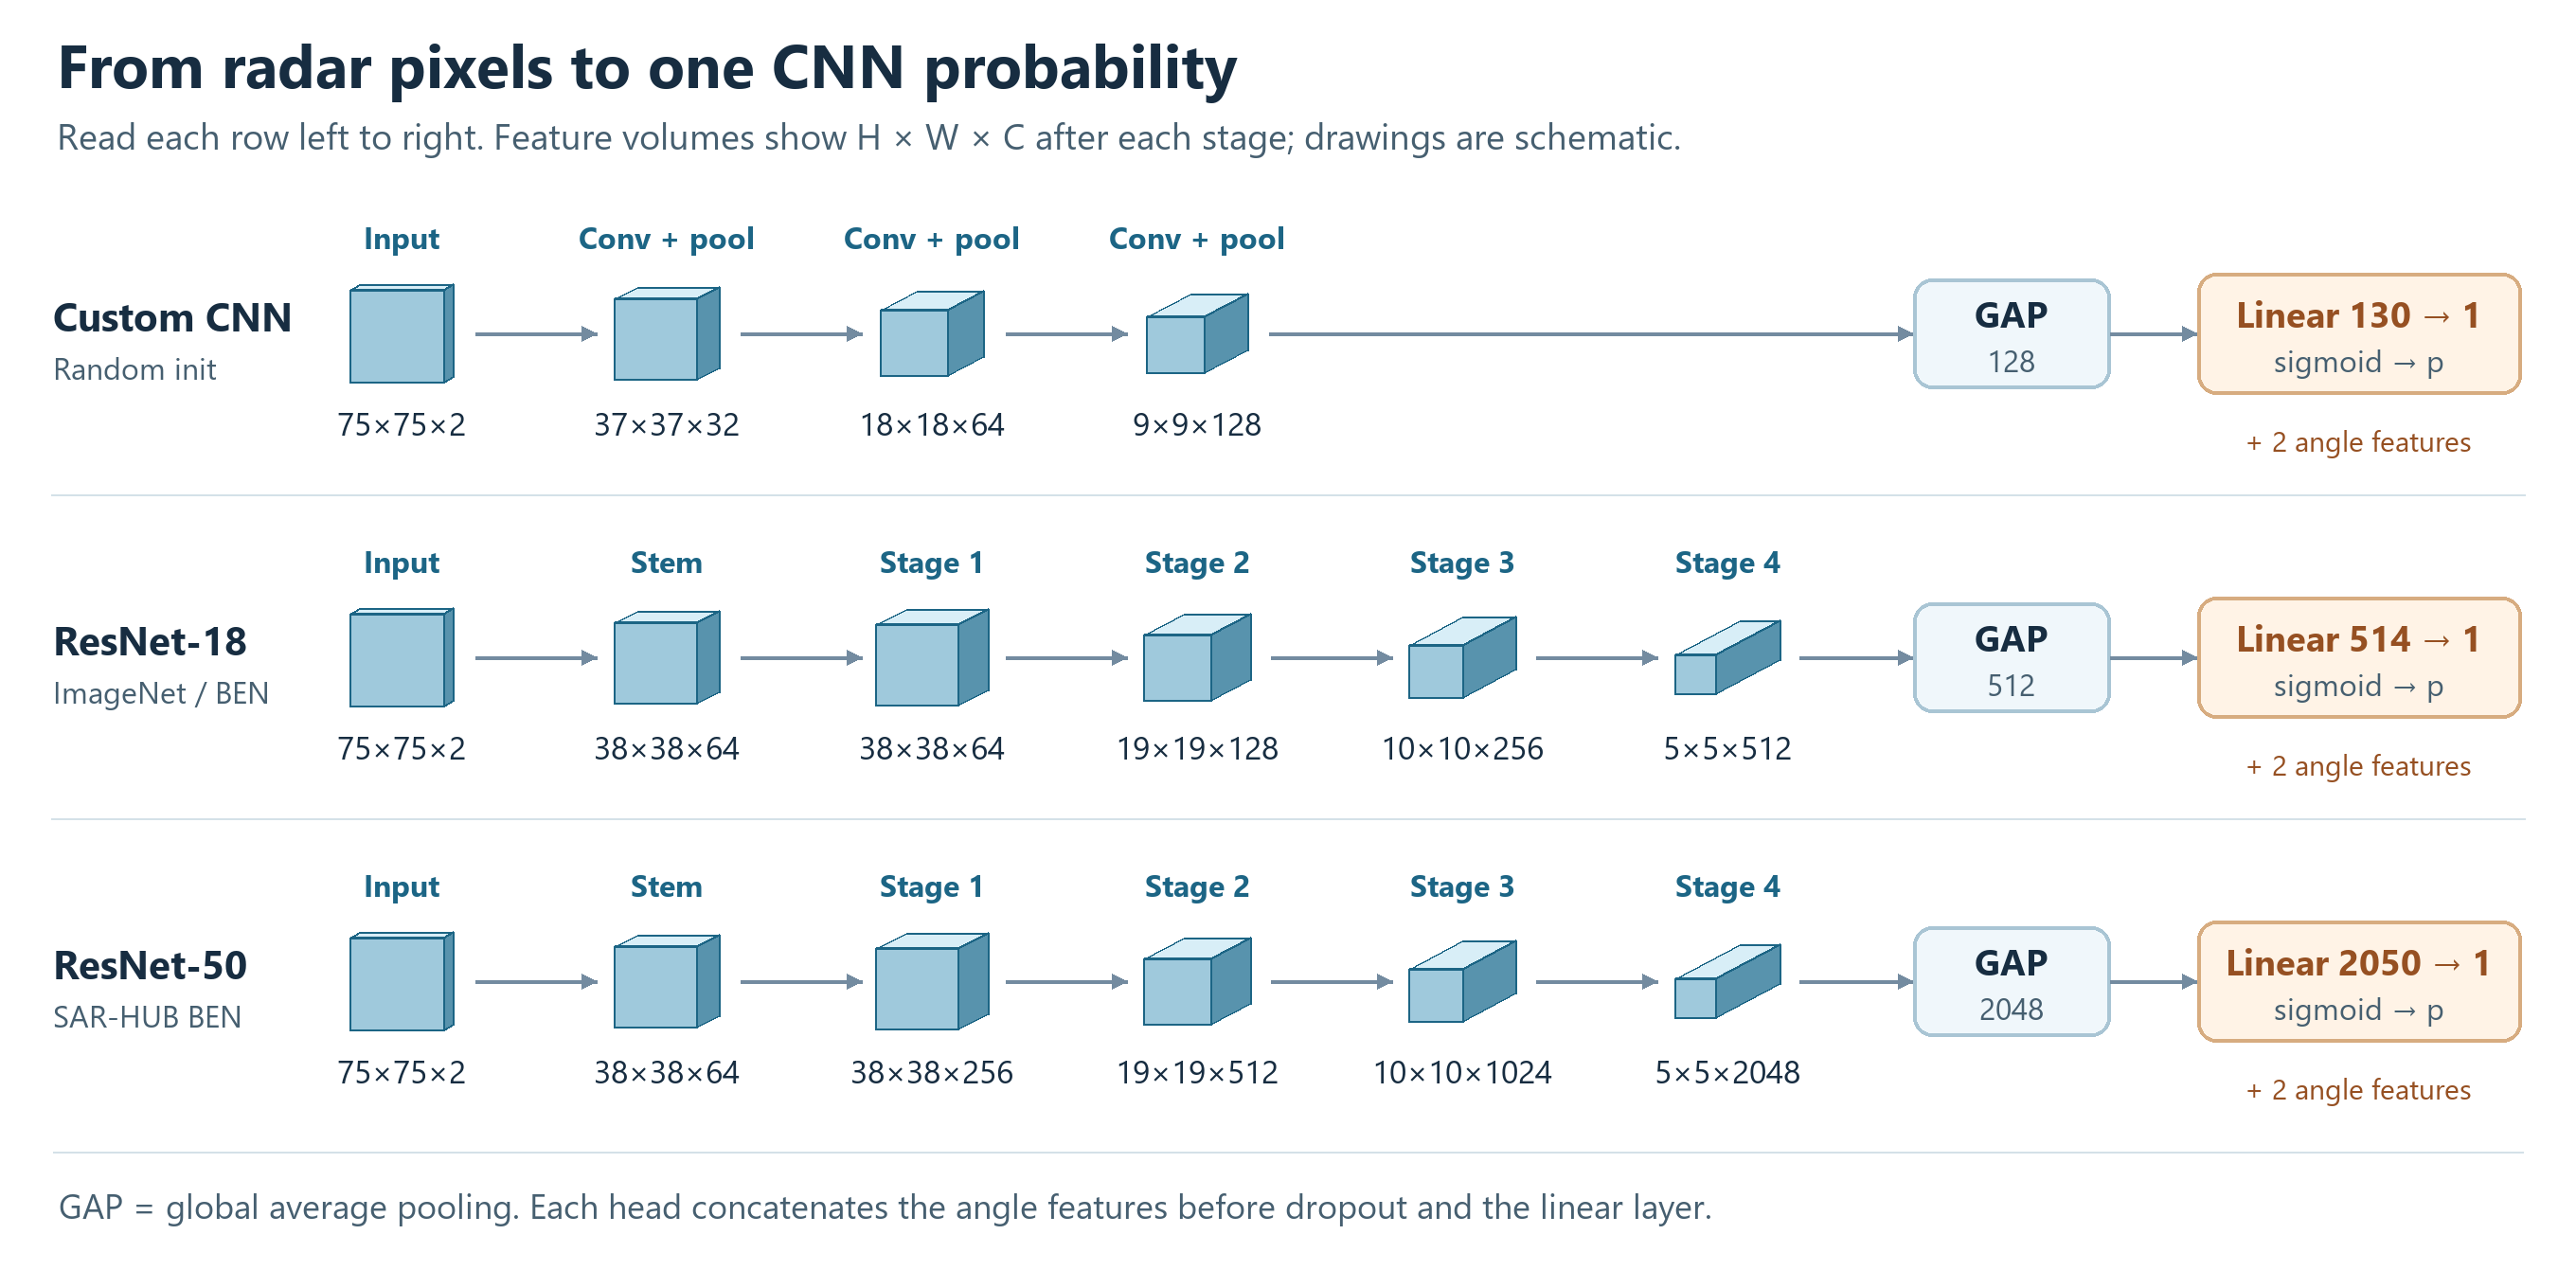

**图 1 · 卷积编码器。** ResNet-18 这一行对应两个独立训练的模型，分别使用 ImageNet 和 SAR-HUB 的预训练权重。两者在第一层使用不同大小的卷积核，后续各阶段的输出尺寸相同。

### 自定义 CNN 与残差网络如何提取图像特征

自定义 CNN 从随机权重开始。每个块依次执行 $3\times3$ 卷积（步长 1、填充 1）、BatchNorm、ReLU 和 $2\times2$ 最大池化。以第一个块为例，卷积把 $75\times75\times2$ 变为 $75\times75\times32$，池化得到 $37\times37\times32$。第三个块输出 $9\times9\times128$。全局平均池化（GAP）把每张特征图的空间位置取均值，得到 128 维向量。

残差块将主分支 $F(x)$ 与捷径分支相加。当尺寸和通道相同时，捷径直接传递 $x$；需要下采样或改变通道数时，捷径使用投影与主分支对齐。两个 ResNet-18 的四个阶段各含 2 个 BasicBlock，每个块的主分支有两层 $3\times3$ 卷积。ResNet-50 的阶段含 3、4、6、3 个 Bottleneck，主分支依次采用 $1\times1$、$3\times3$、$1\times1$ 卷积。所有 ResNet 均移除初始最大池化，保留更高的空间分辨率。

| CNN | 双通道输入怎样进入预训练骨干 | GAP 输出 | 拼接入射角后的分类头 |
|---|---|---:|---|
| 自定义 CNN | 首层直接学习 HH、HV 两通道 | 128 | 130 → Dropout 0.25 → Linear(130, 1) |
| ImageNet ResNet-18 | 重新初始化 $3\times3$、步长 2 的双通道首层，后续骨干载入 ImageNet 权重 | 512 | 514 → Dropout 0.50 → Linear(514, 1) |
| SAR-HUB BEN ResNet-18 | 从 BigEarthNet-S1 权重开始，将三通道首层折合成双通道 $7\times7$ 卷积，步长 2 | 512 | 514 → Dropout 0.50 → Linear(514, 1) |
| SAR-HUB BEN ResNet-50 | 使用相同的首层折合方式，四个阶段为 Bottleneck | 2,048 | 2,050 → Dropout 0.50 → Linear(2050, 1) |

SAR-HUB 的首层变换等价于把 $[HH, HV, (HH+HV)/2]$ 输入原三通道卷积。若原卷积的三组通道权重为 $W_1,W_2,W_3$，则双通道卷积的权重为 $W_1+W_3/2$ 和 $W_2+W_3/2$。三个预训练骨干均全量微调。

**入射角在 GAP 之后接入。** 两个数分别为角度缺失标记、标准化后的角度值。缺失值以当前训练子集已知角度的中位数填充，再用该子集已知角度的均值与标准差标准化。拼接后的向量经过 dropout 和一个线性层，得到一个 logit $z$。推理时 $\sigma(z)$ 就是该 CNN 对该方向图像的冰山概率。

In [8]:
from torch import nn
from torchvision.models import resnet18, resnet50

USE_ANGLE = True
DROPOUT = 0.5
EPOCHS, BATCH = 24, 64
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
if MODE == "full":
    labels=torch.tensor(y,device=device,dtype=torch.float32)
    imagenet_state = torch.load(WEIGHTS / "imagenet" / "resnet18-f37072fd.pth",
                               map_location="cpu", weights_only=True)
    states = {name: torch.load(WEIGHTS / "sarhub" / file, map_location="cpu", weights_only=True)
              for name, file in [("BEN18","ResNet18_BEN.pth"), ("BEN50","ResNet50_BEN.pth")]}

    aug_images, augmented = load_split(DATA, "train_aug_hflip_vflip_rot180", 4 * len(train))
    parents = train.set_index("id")
    variants = ("", "_h", "_v", "_r180")
    expected_ids = {parent + suffix for parent in parents.index for suffix in variants}
    assert set(augmented.id) == expected_ids and augmented.id.is_unique
    parent_idx = pd.Index(train.id).get_indexer(augmented.id.str.split("_").str[0])
    assert (parent_idx >= 0).all()
    assert np.array_equal(augmented.is_iceberg, y[parent_idx])
    assert np.allclose(augmented.inc_angle, train.inc_angle.to_numpy()[parent_idx], equal_nan=True)
    original_rows = pd.Index(augmented.id).get_indexer(train.id)
    assert torch.equal(aug_images[original_rows], images)
    parent_device = torch.tensor(parent_idx, device=device)
    print(f"{len(train)} original IDs, {len(augmented)} offline training views.")
    view_rows = np.column_stack([pd.Index(augmented.id).get_indexer(train.id + suffix) for suffix in variants])
    assert (view_rows >= 0).all() and np.array_equal(view_rows[:,0], original_rows)

In [9]:
class IcebergCNN(nn.Module):
    def __init__(self):
        super().__init__()
        blocks = []
        for incoming, outgoing in [(2, 32), (32, 64), (64, 128)]:
            blocks.extend([nn.Conv2d(incoming, outgoing, 3, padding=1, bias=False),
                           nn.BatchNorm2d(outgoing), nn.ReLU(), nn.MaxPool2d(2)])
        self.encoder = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(0.25), nn.Linear(128 + (2 if USE_ANGLE else 0), 1))

    def forward(self, x, angle):
        features = torch.cat([self.encoder(x), angle], dim=1)
        return self.head(features).flatten(), features

def angle_features(series, reference):
    observed = reference.dropna()
    normalized = (series.fillna(observed.median()) - observed.mean()) / observed.std(ddof=0)
    return torch.tensor(np.column_stack([series.isna(), normalized]), dtype=torch.float32, device=device)


class IcebergResNet(nn.Module):
    def __init__(self, name):
        super().__init__()
        if name in states:
            state = states[name]
            self.encoder = (resnet50 if name == "BEN50" else resnet18)(weights=None)
            self.encoder.fc = nn.Linear(self.encoder.fc.in_features, state['fc.weight'].shape[0])
            self.encoder.load_state_dict(state, strict=True)
            # Encode [HH, HV, (HH+HV)/2] exactly with a two-channel convolution.
            w = self.encoder.conv1.weight.detach().clone()
            self.encoder.conv1 = nn.Conv2d(2, 64, 7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                self.encoder.conv1.weight.copy_(w[:, :2] + 0.5 * w[:, 2:3])
        else:
            self.encoder = resnet18(weights=None)
            self.encoder.load_state_dict(imagenet_state, strict=True)
            self.encoder.conv1 = nn.Conv2d(2, 64, 3, stride=2, padding=1, bias=False)
        self.encoder.maxpool = nn.Identity()
        self.encoder.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear((2048 if name == "BEN50" else 512) + (2 if USE_ANGLE else 0), 1))

    def forward(self, pixels, angle):
        features = torch.cat((self.encoder(pixels), angle), dim=1)
        return self.head(features).flatten()

### 训练增强与四方向 TTA

训练时，每张原图及其水平翻转、垂直翻转、旋转 180° 始终分到同一折。仅用当前训练子集的原始图像估计 HH、HV 的均值和标准差，并将同一组参数用于该次训练和推理。二元交叉熵直接接收 logit。

| 训练设置 | 自定义 CNN | 三个预训练 ResNet |
|---|---:|---:|
| Epoch / batch size | 24 / 48 | 24 / 64 |
| 优化器 / 初始学习率 | AdamW / 0.001 | AdamW / 0.0002 |
| Weight decay | 0.0001 | 0.01 |
| 学习率策略 / 二元标签 | 固定 / 0、1 | 余弦退火至 0.00002 / 0.02、0.98 |

验证和测试时，每个模型分别看四个方向，先对各自的 logit 取 sigmoid，再平均四个概率：
$$p_{\rm CNN}(x)=\tfrac14\sum_{v\in\{\mathrm{orig},\,H,\,V,\,180^\circ\}}\sigma(z_v).$$
因此每张图、每种 CNN 向下一层提供 **一个** 冰山概率。

In [10]:
def fit_predict(model_name, fit, query, seed, test_data=None, mean_dtype=None):
    torch.manual_seed(seed)
    if USE_ANGLE:
        angle = angle_features(train.inc_angle, train.inc_angle.iloc[fit])
    else:
        angle = torch.empty((len(y), 0), device=device)
    sd, mean = torch.std_mean(images[fit], dim=(0,2,3), correction=0, keepdim=True)
    x = ((aug_images.to(device) - mean.to(device)) / sd.to(device)).contiguous(memory_format=torch.channels_last)
    custom = model_name == "custom"
    net = (IcebergCNN() if custom else IcebergResNet(model_name)).to(device, memory_format=torch.channels_last)
    opt = torch.optim.AdamW(net.parameters(), lr=.001 if custom else .0002,
                            weight_decay=.0001 if custom else .01)
    sched = None if custom else torch.optim.lr_scheduler.CosineAnnealingLR(opt,EPOCHS,eta_min=.00002)
    fit_views = np.flatnonzero(np.isin(parent_idx, fit))
    assert len(fit_views) == 4 * len(fit) and not np.isin(parent_idx[fit_views], query).any()
    indices = torch.as_tensor(fit_views, device=device)
    net.train()
    for epoch in range(EPOCHS):
        for idx in indices[torch.randperm(len(indices),device=device)].split(48 if custom else 64):
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type,dtype=torch.bfloat16,
                                enabled=device.type=="cuda" and torch.cuda.is_bf16_supported()):
                pred = net(x[idx], angle[parent_device[idx]])
                logits = pred[0] if custom else pred
                target = labels[parent_device[idx]] if custom else labels[parent_device[idx]]*.96+.02
                loss = nn.functional.binary_cross_entropy_with_logits(logits,target)
            loss.backward()
            opt.step()
        if sched is not None:
            sched.step()
    net.eval()
    with torch.inference_mode():
        out = []
        for idx in np.array_split(query, 10):
            views = []
            for rows in view_rows[idx].T:
                pred = net(x[rows], angle[idx])
                views.append((pred[0] if custom else pred).sigmoid().cpu().numpy())
            out.append(np.mean(views, axis=0, dtype=mean_dtype))
    valid_probs = np.concatenate(out)
    if test_data is None:
        return valid_probs
    test_images, test = test_data
    test_angle = angle_features(test.inc_angle, train.inc_angle.iloc[fit])
    test_probs = []
    with torch.inference_mode():
        for start in range(0, len(test), BATCH):
            sl = slice(start, start + BATCH)
            raw = (test_images[sl].to(device) - mean.to(device)) / sd.to(device)
            views = []
            for dims in [(), (-1,), (-2,), (-2,-1)]:
                pred = net(raw.flip(dims) if dims else raw, test_angle[sl])
                views.append((pred[0] if custom else pred).sigmoid().cpu().numpy())
            test_probs.append(np.mean(views, axis=0))
    return valid_probs, np.concatenate(test_probs)

## 3 · 两套 XGBoost 如何使用 CNN、图像统计量和角度

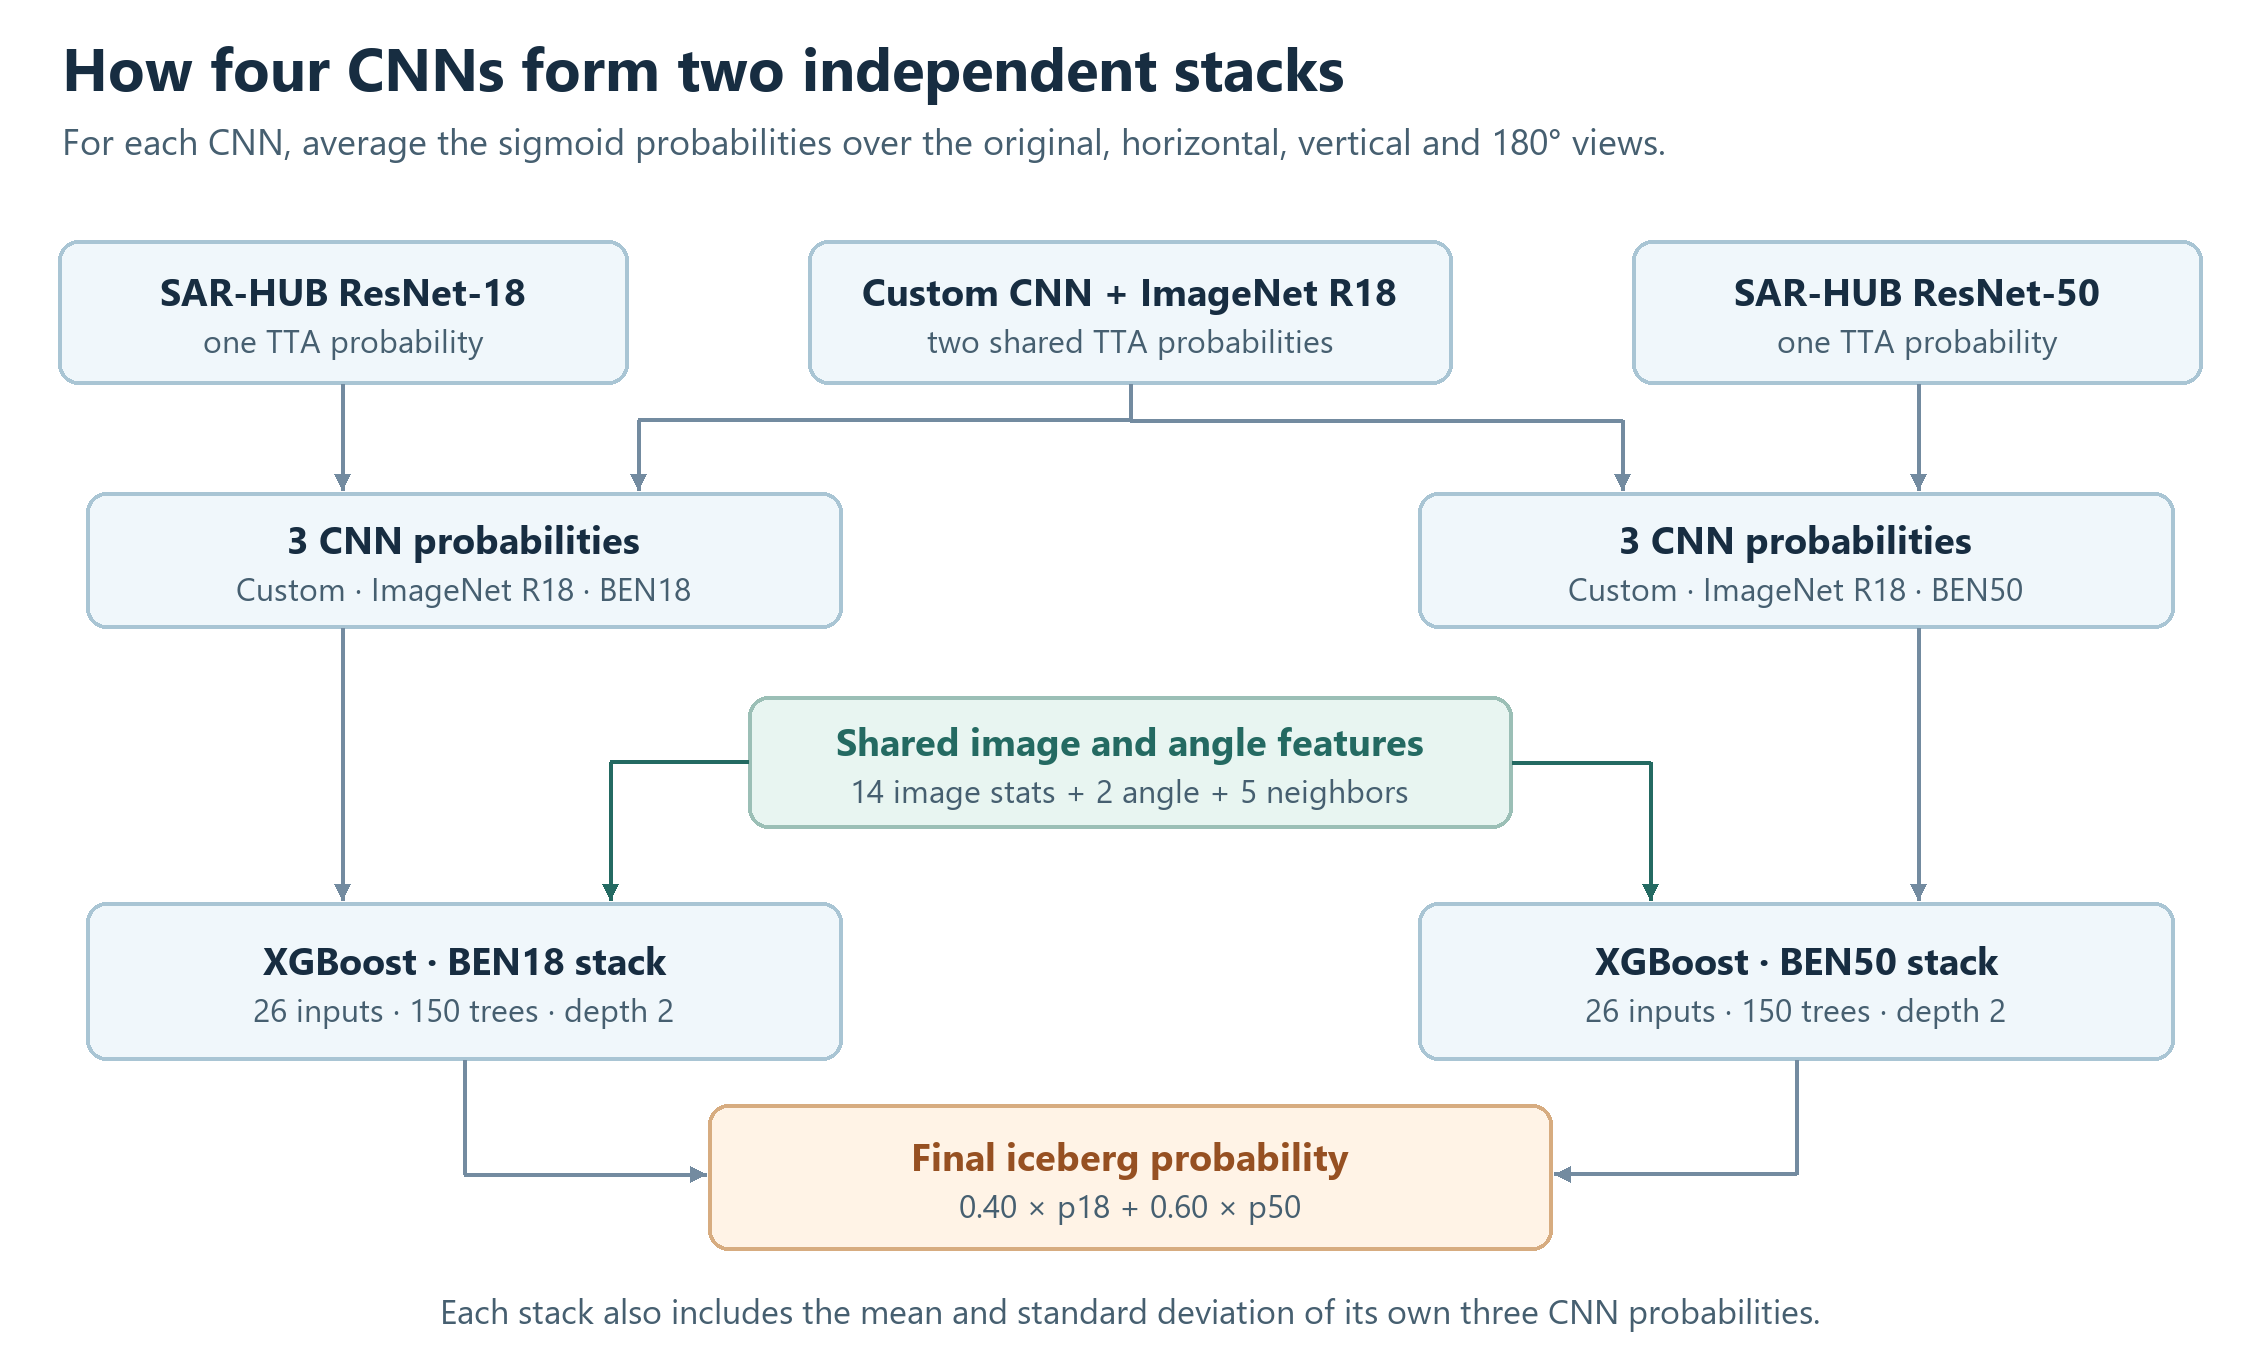

**图 2 · 概率堆叠与最终融合。** 两套方案共享自定义 CNN 和 ImageNet ResNet-18 的预测。左侧第三个 CNN 是 SAR-HUB ResNet-18，右侧第三个是 SAR-HUB ResNet-50。两套 XGBoost 各自拟合，各自输出一个冰山概率。图中的 $p_{18}$、$p_{50}$ 均指对应 **整套 XGBoost** 的输出。

### 每套 XGBoost 的 26 个输入

| 特征组 | 个数 | 具体内容 |
|---|---:|---|
| CNN 概率及其一致性 | 5 | 该套方案的 3 个 TTA 概率，以及这 3 个概率的均值和标准差 |
| 原图像素统计量 | 14 | HH、HV 各取均值、标准差、最小值、最大值及 10%、50%、90% 分位数 |
| 入射角 | 2 | 原始角度、缺失标记；XGBoost 可直接处理缺失值 |
| 多尺度入射角近邻 | 5 | 最近角度的绝对距离、距离 ≤ 0.01° 的参考样本数、$k=1,5,15$ 的平滑冰山比例 |

举例来说，为验证图构造 $k=5$ 特征时，先在允许使用的已知角度训练样本中找到第 5 近的角度距离，再纳入距离不超过该值的所有样本（包含并列）。若其中有 $m$ 张图、$s$ 张冰山，参考样本冰山率为 $\pi$，特征值为 $(s+5\pi)/(m+5)$。查询图缺少角度时，五个近邻特征均设为缺失。实现按历史列顺序保存 $k=5,1,15$。

两套 XGBoost 都使用 **150 棵树、最大深度 2、学习率 0.05**，并采用 `min_child_weight=3`、`reg_lambda=2`。浅树可以学习 CNN 预测与角度、图像亮度特征之间的条件关系。

In [11]:
angles=train.inc_angle.to_numpy()
def image_stats(images):
    flat = images.numpy().reshape(len(images), 2, -1)
    return np.column_stack([flat.mean(2), flat.std(2), flat.min(2), flat.max(2),
                            *np.quantile(flat,[.1,.5,.9],axis=2)])

def stack_features(p, stats, frame, nearby):
    cols = np.column_stack([p, p.mean(1), p.std(1), stats, frame.inc_angle, frame.inc_angle.isna(), nearby])
    assert cols.shape == (len(frame), 26)
    return cols

def make_xgb():
    return XGBClassifier(n_estimators=150, max_depth=2, learning_rate=.05, reg_lambda=2,
                         min_child_weight=3, base_score=.5, tree_method="exact",
                         n_jobs=1, random_state=SEED)  # 多线程在 macOS 上与 torch 各自的 libomp 冲突致段错误；exact 结果与线程数无关

stats = image_stats(images)
# Column order preserves the original five-neighbor ablation.
neighbor_scales = (5, 1, 15)
def neighbors(query, reference, angles=angles):
    assert not np.intersect1d(query, reference).size
    reference = reference[np.isfinite(angles[reference])]
    result = np.full((len(query), 2 + len(neighbor_scales)), np.nan)
    prior = y[reference].mean()
    for i, row in enumerate(query):
        if not np.isfinite(angles[row]):
            continue
        distances = np.abs(angles[reference] - angles[row])
        result[i, :2] = distances.min(), (distances <= .01).sum()
        for column, k in enumerate(neighbor_scales, start=2):
            cutoff = np.partition(distances, k - 1)[k - 1]
            selected = reference[distances <= cutoff]
            result[i, column] = (y[selected].sum() + 5 * prior) / (len(selected) + 5)
    return result

## 4 · 五折折外验证：让二层模型看到未参与 CNN 训练的预测

以外层第 0 折作为验证集为例。给第 3 折构造 XGBoost 训练特征时，CNN 只在第 1、2、4 折训练，同时留出第 0 和第 3 折；第 3 折的角度近邻标签也只取自第 1、2、4 折。给第 0 折构造验证特征时，平均四个均未看过第 0 折的折对模型预测，角度近邻则查询其他四折。最后，用其他四折的特征和标签拟合 XGBoost，预测第 0 折。轮流留出每一折，就得到所有 1,604 张图的**折外概率（OOF）**。

每个划分有 $\binom{5}{2}=10$ 个折对，每个折对训练四种 CNN，两套 XGBoost 复用其中的公共分支。seed 42 对应最终提交所用划分；seed 2026 将同一批训练图重新分折，用于观察结论对划分的敏感度。两次验证共用训练样本，计算验证均值时各占一半。

按上述两套划分完整重跑，验证阶段需要训练 80 个 CNN 实例，测试提交阶段另训练 20 个；两套堆叠模型共享的 CNN 概率都只计算一次。

In [12]:
def folds_for(seed):
    if seed == SEED:
        return original_folds
    split = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
    folds = np.full(len(y), -1)
    for fold, (_, held) in enumerate(split.split(train.id, y)):
        folds[held] = fold
    return folds

def load_cached_pairs(seed):
    keys = ["id", "excluded_a", "excluded_b"]
    def read(path):
        return pd.read_csv(CACHE_INPUT / path, dtype={"id": str}, float_precision="round_trip")
    if seed == SEED:
        base = read("stacking_xgb_grid_cnn_tta.csv").rename(columns={"BEN": "BEN18"})
        ben50 = read("stacking_ben50_full_tta.csv").rename(columns={"ResNet50": "BEN50"})
        merged = base.merge(ben50, on=keys, validate="one_to_one", how="outer")
    else:
        merged = read(f"stacking_seed{seed}_directional_tta.csv")
        for name in families:
            cols = [f"{name}_{d}" for d in ("original", "hflip", "vflip", "rot180")]
            merged[name] = merged[cols].to_numpy().mean(axis=1)
    assert not merged.duplicated(keys).any() and len(merged) == (N_FOLDS - 1) * len(y)
    return merged

def pair_predictions_for(seed, folds):
    cached = load_cached_pairs(seed) if MODE == "cached" else None
    pairs = {}
    for a, b in combinations(range(N_FOLDS), 2):
        held = (folds == a) | (folds == b)
        query = np.flatnonzero(held)
        values = np.full((len(y), len(families)), np.nan)
        if cached is None:
            fit = np.flatnonzero(~held)
            for j, name in enumerate(families):
                values[query,j] = fit_predict(name, fit, query, SEED + 5*a + b,
                                              mean_dtype=None if seed == SEED else np.float64)
            print(f"Seed {seed}, trained fold pair {a}, {b}", flush=True)
        else:
            rows = cached.loc[(cached.excluded_a == a) & (cached.excluded_b == b)].set_index("id")
            assert rows.index.is_unique and set(rows.index) == set(train.id[held])
            rows = rows.loc[train.id[held]]
            assert np.array_equal(rows.fold, folds[held])
            values[held] = rows[families].to_numpy()
        assert np.all((values[held] >= 0) & (values[held] <= 1))
        pairs[a,b] = values
    return pairs

In [ ]:
def evaluate_split(seed):
    folds = folds_for(seed)
    pairs = pair_predictions_for(seed, folds)
    oof = pd.DataFrame(index=train.index, columns=stack_columns, dtype=float)
    for outer in range(N_FOLDS):
        valid = folds == outer
        probs = np.full((len(y), len(families)), np.nan)
        nearby = np.full((len(y), 5), np.nan)
        held = []
        for inner in range(N_FOLDS):
            if inner == outer:
                continue
            mask = folds == inner
            pair = pairs[tuple(sorted((outer, inner)))]
            probs[mask] = pair[mask]
            held.append(pair[valid])
            nearby[mask] = neighbors(np.flatnonzero(mask), np.flatnonzero(~(valid | mask)))
        probs[valid] = np.mean(held, axis=0)
        nearby[valid] = neighbors(np.flatnonzero(valid), np.flatnonzero(~valid))
        for name, cols in stack_columns.items():
            x = stack_features(probs[:, cols], stats, train, nearby)
            model = make_xgb().fit(x[~valid], y[~valid])
            oof.loc[valid, name] = model.predict_proba(x[valid])[:, 1]
    assert np.isfinite(oof.to_numpy()).all()
    assert oof.ge(0).all().all() and oof.le(1).all().all()
    oof.index = pd.Index(train.id, name="id")
    return oof

oof_by_seed = {seed: evaluate_split(seed) for seed in CV_SEEDS}
print(f"Ready: {len(oof_by_seed)} splits, {len(train):,} out-of-fold probability pairs per split.")

## 5 · 融合权重和本地 log loss

对每个训练样本，保留两个 XGBoost 的折外概率。令 $w$ 表示 **BEN50 整套方案**的权重，计算 $p(w)=(1-w)p_{18}+w p_{50}$。$w=0$ 和 $w=1$ 分别给出单独方案的表现，$w=0.5$ 是两套方案等权的对照。改变 $w$ 只需要重新加权同一批概率。

下表按 seed 把所有样本的折外预测合在一起计算 log loss。后面的分折表展示各验证折从 50/50 到 40/60 的变化。差值小于零表示 loss 下降。**报告和提交固定使用 $w=0.60$**；历史候选权重仅用于呈现实验过程。

In [ ]:
CANDIDATE_WEIGHTS = [0, 0.25, 0.40, 0.50, 0.60, 0.70, 0.75, 1]

reference = Decimal("0.5")
selected = EXPORT_WEIGHT
weights = {Decimal(str(w)) for w in CANDIDATE_WEIGHTS} | {reference, selected}
if not all(w.is_finite() and 0 <= w <= 1 for w in weights):
    raise ValueError("Every weight must be a finite number between 0 and 1.")
weights = sorted(weights)

In [ ]:
pool_records, fold_records = [], []
for seed, oof in oof_by_seed.items():
    assert oof.index.tolist() == train.id.tolist()
    split = folds_for(seed)
    for weight in weights:
        w = float(weight)
        p = (1-w) * oof.BEN18.to_numpy() + w * oof.BEN50.to_numpy()
        pool_records.append((w, seed, log_loss(y, p)))
        for fold in range(N_FOLDS):
            mask = split == fold
            fold_records.append((seed, fold, w, log_loss(y[mask], p[mask])))

pooled = pd.DataFrame(pool_records, columns=["w50", "seed", "loss"])
summary = pooled.pivot(index="w50", columns="seed", values="loss")
summary["mean"] = summary[list(CV_SEEDS)].mean(axis=1)
summary["delta_vs_50_50"] = summary["mean"] - summary.loc[0.5, "mean"]
print(summary.to_string(float_format=lambda v: f"{v:.8f}"))
fold_table = pd.DataFrame(fold_records, columns=["seed", "fold", "w50", "loss"])
fold_table = fold_table.pivot(index=["seed", "fold"], columns="w50", values="loss")
comparison = fold_table[list(dict.fromkeys([0.5, float(selected)]))].copy()
comparison["delta"] = fold_table[float(selected)] - fold_table[0.5]
print(comparison.to_string(float_format=lambda v: f"{v:.6f}"))

In [ ]:
from IPython.display import SVG, display

def weight_plot(table):
    width, height = 660, 305
    left, right, top, bottom = 86, 632, 30, 245
    curves = [(42, "#1967a3"), (2026, "#9c4512"), ("mean", "#333333")]
    values = table[[42, 2026, "mean"]].to_numpy()
    low, high = values.min() - 0.0001, values.max() + 0.0001
    def x(weight):
        return left + weight * (right - left)
    def y(loss):
        return bottom - (loss-low)/(high-low) * (bottom-top)
    items = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" font-family="sans-serif" font-size="12">',
             '<rect width="100%" height="100%" fill="white"/>',
             '<text x="10" y="15">Pooled OOF log loss</text>']
    for loss in np.linspace(low, high, 5):
        items += [f'<path d="M{left},{y(loss)} H{right}" stroke="#dddddd"/>',
                  f'<text x="{left-8}" y="{y(loss)+4}" text-anchor="end">{loss:.5f}</text>']
    for w in np.linspace(0, 1, 6):
        items.append(f'<text x="{x(w)}" y="{bottom+20}" text-anchor="middle">{w:.0%}</text>')
    for j, (label, color) in enumerate(curves):
        points = " ".join(f"{x(w):.2f},{y(v):.2f}" for w, v in table[label].items())
        dash = 'stroke-dasharray="5 4"' if label == "mean" else ""
        items.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2" {dash}/>')
        for w, v in table[label].items():
            items.append(f'<circle cx="{x(w)}" cy="{y(v)}" r="3" fill="{color}"/>')
        key = "Mean" if label == "mean" else f"Seed {label}"
        items.append(f'<text x="{370+95*j}" y="15" fill="{color}">{key}</text>')
    items += ['<text x="360" y="292" text-anchor="middle">SAR-HUB ResNet-50 weight</text>', '</svg>']
    return SVG("".join(items))

display(weight_plot(summary))

### 60/40 相对 50/50 改变了多少？

| BEN50 权重 | seed 42 OOF | seed 2026 OOF | 两次划分均值 |
|---|---:|---:|---:|
| 50% | 0.11623357 | **0.11696841** | 0.11660099 |
| **60%（最终）** | **0.11611506** | 0.11706903 | **0.11659204** |

将 BEN50 的权重从 50% 提高到 60%，seed 42 的整体 log loss 下降约 0.000119，seed 2026 的结果则上升约 0.000101。两次划分的均值仅下降约 0.000009。继续提高到 70% 时，seed 42 的结果更低，但两次划分的均值回升到 0.11667170。相邻权重的差异很小，具体哪一个更优会随划分变化。

Kaggle 实际提交中，50/50 的 Public / Private 分别为 0.12124 / 0.09746，40/60 的结果为 **0.12138 / 0.09742**。Private log loss 略微降低，Public 略微升高。本文按项目最终选择归档 40/60。

## 6 · 从测试图像到 Kaggle CSV

**全量路径**使用固定 seed 42 的五折。每一折训练四种 CNN，保留该折训练样本之外的 CNN 预测，同时对 `test.json` 的 8,424 张图进行四方向 TTA。这样得到完整的训练集 OOF 概率矩阵（1,604 × 4）和测试概率张量（5 × 8,424 × 4）。先沿折维度平均测试概率，再为每套 XGBoost 选取自己的三列。

训练集角度近邻逐折计算；测试图的近邻只查询训练集已知标签。两套 XGBoost 分别在全部训练样本的 OOF 特征上拟合，再对测试集预测。最后按官方模板的 ID 对齐并计算 $0.40p_{18}+0.60p_{50}$。seed 2026 只出现在前面的验证，不进入这份提交。

**缓存路径**读取 `inputs/cached/test_branch_probabilities.csv` 中两列按 ID 对齐的测试集分支概率，直接复算同一融合。为了保留原提交写入的十进制精度，融合阶段以 `Decimal` 读取和写出概率。

In [2]:
def read_branch_probabilities():
    frame = pd.read_csv(CACHE_INPUT / "test_branch_probabilities.csv", dtype=str, keep_default_na=False)
    assert list(frame) == ["id", "BEN18", "BEN50"]
    assert frame.id.is_unique and set(frame.id) == set(template.id)
    aligned = frame.set_index("id").loc[template.id]
    return {name: aligned[name].map(Decimal) for name in stack_columns}


def train_submission():
    test_images, test = load_split(DATA, "test", len(template))
    assert test.id.is_unique and set(test.id) == set(template.id)
    train_probs = np.full((len(y), len(families)), np.nan)
    test_folds = np.full((N_FOLDS, len(test), len(families)), np.nan)
    train_nearby = np.full((len(y), 5), np.nan)
    for fold in range(N_FOLDS):
        fit = np.flatnonzero(original_folds != fold)
        query = np.flatnonzero(original_folds == fold)
        train_nearby[query] = neighbors(query, fit)
        for j, name in enumerate(families):
            train_probs[query,j], test_folds[fold,:,j] = fit_predict(
                name, fit, query, SEED + fold, (test_images, test))
        print(f"Completed submission fold {fold}", flush=True)
    assert np.isfinite(train_probs).all() and np.isfinite(test_folds).all()
    test_nearby = neighbors(len(y) + np.arange(len(test)), np.arange(len(y)),
                            np.concatenate([angles, test.inc_angle]))
    test_stats = image_stats(test_images)
    test_probs = test_folds.mean(axis=0)
    result = {}
    for name, cols in stack_columns.items():
        x = stack_features(train_probs[:, cols], stats, train, train_nearby)
        model = make_xgb().fit(x, y)
        x_test = stack_features(test_probs[:, cols], test_stats, test, test_nearby)
        # Match the float32 text precision used by the original branch submissions.
        values = model.predict_proba(x_test)[:, 1].astype(str)
        result[name] = pd.Series(values, index=test.id).loc[template.id].map(Decimal)
    return result

prob = read_branch_probabilities() if MODE == "cached" else train_submission()

NameError: name 'MODE' is not defined

### 写出并核验提交

输出文件名包含两个分支的百分比。写入前检查列名、行数、ID 顺序、概率范围及逐行加权结果。缓存复现与全量重训分别写入 `outputs/final/cached/` 和 `outputs/final/full/`；缓存模式还会用历史提交的 SHA-256 校验导出的 CSV 是否逐字节一致。Kaggle 所需的两列为 `id,is_iceberg`。

In [ ]:
for branch in prob.values():
    assert branch.index.tolist() == template.id.tolist()
    assert all(p.is_finite() and 0 <= p <= 1 for p in branch)

w50 = EXPORT_WEIGHT
w18 = Decimal(1) - w50
blend = w18 * prob["BEN18"] + w50 * prob["BEN50"]
output = ROOT / "outputs" / "final" / MODE / SUBMISSION_NAME
output.parent.mkdir(parents=True, exist_ok=True)
with NamedTemporaryFile(dir=output.parent, delete=False, mode="w", newline="", encoding="utf-8") as handle:
    pending = Path(handle.name)

try:
    with pending.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle, lineterminator="\n")
        writer.writerow(["id", "is_iceberg"])
        writer.writerows((image_id, format(p, "f")) for image_id, p in blend.items())
    saved = pd.read_csv(pending, dtype=str, keep_default_na=False)
    assert list(saved) == list(template) and saved.id.equals(template.id)
    assert len(saved) == 8424 and saved.id.is_unique
    checked = saved.is_iceberg.map(Decimal)
    assert all(p.is_finite() and 0 <= p <= 1 for p in checked)
    assert checked.tolist() == [a + w50 * (b - a) for a, b in zip(prob["BEN18"], prob["BEN50"])]
    if MODE == "cached":
        expected_sha256 = "f27703ba313001e800b76450a45ef7bb75d9ac2577ba6a923c8f354cfb83fdc5"
        assert hashlib.sha256(pending.read_bytes()).hexdigest() == expected_sha256, "缓存融合与历史提交不一致"
    pending.replace(output)
finally:
    pending.unlink(missing_ok=True)

print(f"{output.as_posix()} | {len(saved):,} rows | BEN18 {w18:.0%} + BEN50 {w50:.0%}")
print(saved.head().to_string(index=False))